In [114]:
!pip install nba_api

In [115]:
# Cell 1 is for the import statements and the setup for the project
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from nba_api.stats.endpoints import leaguegamefinder
from nba_api.stats.static import teams
import time


In [116]:
# I pulled the data into a csv from pull_data.py to turn the api into a CSV readable file so that the api wouldnt flag my pulls as a bot's and thus cancel the data pulling
# This serves to read from the csv and take the previous 5 seasons

df = pd.read_csv('raw_games.csv')
print(f"Total rows: {len(df)}")
print(df.head())

Total rows: 14118
   SEASON_ID     TEAM_ID TEAM_ABBREVIATION           TEAM_NAME   GAME_ID  \
0      22019  1610612748               MIA          Miami Heat  21901316   
1      22019  1610612745               HOU     Houston Rockets  21901315   
2      22019  1610612743               DEN      Denver Nuggets  21901318   
3      22019  1610612755               PHI  Philadelphia 76ers  21901315   
4      22019  1610612761               TOR     Toronto Raptors  21901318   

    GAME_DATE      MATCHUP WL  MIN  PTS  ...  FT_PCT  OREB  DREB  REB  AST  \
0  2020-08-14    MIA @ IND  L  240   92  ...   0.741    14    34   48   14   
1  2020-08-14  HOU vs. PHI  L  240   96  ...   0.875     1    26   27   25   
2  2020-08-14    DEN @ TOR  L  240  109  ...   0.913     9    32   41   27   
3  2020-08-14    PHI @ HOU  W  241  134  ...   0.818     8    43   51   31   
4  2020-08-14  TOR vs. DEN  W  241  117  ...   0.643    13    38   51   27   

   STL  BLK  TOV  PF  PLUS_MINUS  
0    6    5   19  15 

In [117]:
# figuring out the dataframe shape, what datatypes are each column, and figuring out if there are missing values I will need to deal with

print(df.shape)
print(df.dtypes)
print(df.isnull().sum())

(14118, 28)
SEASON_ID              int64
TEAM_ID                int64
TEAM_ABBREVIATION     object
TEAM_NAME             object
GAME_ID                int64
GAME_DATE             object
MATCHUP               object
WL                    object
MIN                    int64
PTS                    int64
FGM                    int64
FGA                    int64
FG_PCT               float64
FG3M                   int64
FG3A                   int64
FG3_PCT              float64
FTM                    int64
FTA                    int64
FT_PCT               float64
OREB                   int64
DREB                   int64
REB                    int64
AST                    int64
STL                    int64
BLK                    int64
TOV                    int64
PF                     int64
PLUS_MINUS           float64
dtype: object
SEASON_ID            0
TEAM_ID              0
TEAM_ABBREVIATION    0
TEAM_NAME            0
GAME_ID              0
GAME_DATE            0
MATCHUP              0
W

In [118]:
# Create HOME and WIN columns, convert date to datatime, sort data
df['GAME_DATE'] = pd.to_datetime(df['GAME_DATE'])
df['HOME'] = df['MATCHUP'].apply(lambda x: 1 if "vs." in x else 0)
df['WIN'] = df['WL'].apply(lambda x: 1 if x == 'W' else 0)

df = df.sort_values(['TEAM_ID', 'GAME_DATE']).reset_index(drop=True)
print("Cleaning complete.")

Cleaning complete.


In [119]:
# Days of rest before each game = current game date minus the team's previous game date.
# No leakage: by the time a game is scheduled, we already know its date and the team's previous game date.
df['REST_DAYS'] = df.groupby('TEAM_ID')['GAME_DATE'].diff().dt.days
df['REST_DAYS'] = df['REST_DAYS'].fillna(3)  # first game of the dataset for a team: assume normal rest
print(df[df['TEAM_ABBREVIATION']=='LAL'][['GAME_DATE','REST_DAYS']].head(10))

      GAME_DATE  REST_DAYS
4698 2019-10-22        3.0
4699 2019-10-25        3.0
4700 2019-10-27        2.0
4701 2019-10-29        2.0
4702 2019-11-01        3.0
4703 2019-11-03        2.0
4704 2019-11-05        2.0
4705 2019-11-08        3.0
4706 2019-11-10        2.0
4707 2019-11-12        2.0


In [120]:
# DATA VERIFICATION - cross check against known real stats


# GSW 2021-22: real record was 53-29, ~111 PPG
gsw_2122 = df[
    (df['TEAM_ABBREVIATION'] == 'GSW') &
    (df['SEASON_ID'].astype(str) == '22021')
]
print(f"GSW 2021-22 games: {len(gsw_2122)} (should be 82)")
print(f"GSW 2021-22 avg PTS: {gsw_2122['PTS'].mean():.1f} (should be ~111)")
print(f"GSW 2021-22 wins: {gsw_2122['WIN'].sum()} (should be 53)")
print(f"GSW 2021-22 losses: {(gsw_2122['WIN']==0).sum()} (should be 29)")
print()

# BOS 2022-23: real record was 57-25, ~117 PPG
bos_2223 = df[
    (df['TEAM_ABBREVIATION'] == 'BOS') &
    (df['SEASON_ID'].astype(str) == '22022')
]
print(f"BOS 2022-23 games: {len(bos_2223)} (should be 82)")
print(f"BOS 2022-23 avg PTS: {bos_2223['PTS'].mean():.1f} (should be ~117)")
print(f"BOS 2022-23 wins: {bos_2223['WIN'].sum()} (should be 57)")
print(f"BOS 2022-23 losses: {(bos_2223['WIN']==0).sum()} (should be 25)")
print()

# LAL 2023-24: real record was 47-35, ~114 PPG
lal_2324 = df[
    (df['TEAM_ABBREVIATION'] == 'LAL') &
    (df['SEASON_ID'].astype(str) == '22023')
]
print(f"LAL 2023-24 games: {len(lal_2324)} (should be 82)")
print(f"LAL 2023-24 avg PTS: {lal_2324['PTS'].mean():.1f} (should be ~114)")
print(f"LAL 2023-24 wins: {lal_2324['WIN'].sum()} (should be 47)")
print(f"LAL 2023-24 losses: {(lal_2324['WIN']==0).sum()} (should be 35)")


#Okay so based on these outputs and comparing to real life stats

GSW 2021-22 games: 82 (should be 82)
GSW 2021-22 avg PTS: 111.0 (should be ~111)
GSW 2021-22 wins: 53 (should be 53)
GSW 2021-22 losses: 29 (should be 29)

BOS 2022-23 games: 82 (should be 82)
BOS 2022-23 avg PTS: 117.9 (should be ~117)
BOS 2022-23 wins: 57 (should be 57)
BOS 2022-23 losses: 25 (should be 25)

LAL 2023-24 games: 82 (should be 82)
LAL 2023-24 avg PTS: 118.0 (should be ~114)
LAL 2023-24 wins: 47 (should be 47)
LAL 2023-24 losses: 35 (should be 35)


In [121]:
# Feature Engineering, ROLLING AVERAGES, the core of the prediction model
# The key is that we cannot use a games own stats to predict it since we don't know the turnout beforehand, but rather we use the previous 5 games as a measure

# Below are the stats we will use to track a teams performance for the rolling averages
# PTS(Points)- offensive output, FG_PCT(Field Goal Percentage)
stat_cols = [
    'PTS',
    'FG_PCT',
    'FT_PCT',
    'FG3_PCT',
    'AST',
    'REB',
    'STL',
    'BLK',
    'TOV',
    'PLUS_MINUS'
]

# Then create a 5 game rolling average for each stat, groupby TEAM_ID calculates each teams 5 game rolling averages seperately
# Shift(1) uses only the past games never the current
for col in stat_cols:
  df[f'{col}_5rolling_average'] = (
      df.groupby('TEAM_ID')[col].transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean()))

print(f"Columns created: {[f'{c}_5rolling_average' for c in stat_cols]}")
print()
print("Sample - LAL rolling points versus actual points: ")
print(df[df['TEAM_ABBREVIATION']=='LAL'][['GAME_DATE','PTS','PTS_5rolling_average']].head(10))

Columns created: ['PTS_5rolling_average', 'FG_PCT_5rolling_average', 'FT_PCT_5rolling_average', 'FG3_PCT_5rolling_average', 'AST_5rolling_average', 'REB_5rolling_average', 'STL_5rolling_average', 'BLK_5rolling_average', 'TOV_5rolling_average', 'PLUS_MINUS_5rolling_average']

Sample - LAL rolling points versus actual points: 
      GAME_DATE  PTS  PTS_5rolling_average
4698 2019-10-22  102                   NaN
4699 2019-10-25   95            102.000000
4700 2019-10-27  120             98.500000
4701 2019-10-29  120            105.666667
4702 2019-11-01  119            109.250000
4703 2019-11-03  103            111.200000
4704 2019-11-05  118            111.400000
4705 2019-11-08   95            116.000000
4706 2019-11-10  104            111.000000
4707 2019-11-12  123            107.800000


In [122]:
#Feature engineering - WIN STREAKS. Essentially win streaks genuinely tracks a team's momentum. Teams on win streaks play with more confidence, better chemistry and opponents plan more against
# them. In the small scale this fetaure will track wins or losses each team has on a streak going into each game, and in the big scale momentum is tracked for the model. This feature definitely is a factor that stats alone cannot produce
# and matter for predictions

def get_streak(series):
  #series is one team's sequential wins or losses (1 or 0) in chronological order
  streak = []
  current = 0

  for val in series:
    # if the result of a game is a win, increment by 1, if the previous game(s) were a losing streak, reset to zero then increment
    # otherwise do the opposite
    if val == 1:
      current = max(0, current) + 1

    else:
      current = min(0, current) - 1
    streak.append(current)

  #shift(1) moves everything forward by so each game gets the value of the streak before that game and not after
  # fillna(0) fills in the missing value for the first game with zero since previous to the first game would be NaN.
  return pd.Series(streak).shift(1).fillna(0).values

# apply get_streak to each team seperately using groupyby and transform functions
df['WIN_STREAK'] = df.groupby('TEAM_ID')['WIN'].transform(get_streak)





# Feature engineering - HOME COURT ADVANTAGE rolling win rate. On the small scale this will calculate each teams rolling win rate at home versus their away win rate over the last ten games
# on the grand scale, some teams perform drastically better at home than away oir vice versa. The model should not only know when a team is home, but also take into account the team's performance at home versus away
#rolling win rate over previous ten games home

df['HOME_WIN_RATE'] = (
    df.groupby(['TEAM_ID', 'HOME'])['WIN'].transform(lambda x: x.shift(1).rolling(10, min_periods = 1).mean())
)




#Feature engineering - Opponent strength. On the smaller scale for each game we look at the rolling avg of points allowed as a measurement of the defnsive strength of the matchup. On the larger scale a team scoring
# 113 ppg can be interpreted in a few ways depending on the matchup between teams. 113 Against a stronger opponent is more impressive than on a team who consistenly gets destroyed.
# First create a points allowed rolling average, simply acquired by looking at the opponents pts in the same game

# create a copy of df with just the columns needed for opponent measuring
opp_df = df[['GAME_ID', 'TEAM_ID', 'PTS']].copy()

# rename columns for the merge so we know what team scored which associated pts
opp_df = opp_df.rename(columns={'TEAM_ID': 'OPPONENT_TEAM_ID', 'PTS': 'OPP_PTS'})

# merge back onto main df using GAME_ID, every game has two rows (one per team), linking each team to their opponent's stats for that game
df = df.merge(opp_df, on='GAME_ID', how='left')

# remove the rows where a team merged with itself
df = df[df['TEAM_ID'] != df['OPPONENT_TEAM_ID']].reset_index(drop=True)

# rolling avg of opponent points allowed = defensive strength metric
df['OPP_PTS_ALLOWED_ROLL5'] = (
    df.groupby('TEAM_ID')['OPP_PTS']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

# VERIFYING NEW FEATURES
print("All features created!")
print(f"Total columns now: {len(df.columns)}")
print(f"Total rows now: {len(df)}")
print()
print("Sample - Lakers feature check:")
print(df[df['TEAM_ABBREVIATION'] == 'LAL'][[
    'GAME_DATE', 'WIN', 'REST_DAYS', 'WIN_STREAK', 'HOME_WIN_RATE', 'OPP_PTS_ALLOWED_ROLL5'
]].head(10))






All features created!
Total columns now: 46
Total rows now: 14118

Sample - Lakers feature check:
      GAME_DATE  WIN  REST_DAYS  WIN_STREAK  HOME_WIN_RATE  \
4698 2019-10-22    0        3.0         0.0            NaN   
4699 2019-10-25    1        3.0        -1.0            NaN   
4700 2019-10-27    1        2.0         1.0       1.000000   
4701 2019-10-29    1        2.0         2.0       1.000000   
4702 2019-11-01    1        3.0         3.0       0.000000   
4703 2019-11-03    1        2.0         4.0       0.500000   
4704 2019-11-05    1        2.0         5.0       0.666667   
4705 2019-11-08    1        3.0         6.0       1.000000   
4706 2019-11-10    0        2.0         7.0       1.000000   
4707 2019-11-12    1        2.0        -1.0       0.750000   

      OPP_PTS_ALLOWED_ROLL5  
4698                    NaN  
4699             112.000000  
4700              99.000000  
4701              99.666667  
4702              97.500000  
4703             100.000000  
4704     

In [123]:
# ELO rating which starts every team at 1500, updates after each game based on the result vs. what was expected.
# A team that beats a strong opponent gains more than beating a weak one. This sysem to me makes more sense for improving accuracy, we can see live matchups based on previous games and is updated constantly after each game.
#The existing features only look at the rolling 5-10 game averages but ELO here is different because its a running score comparing a team's strength, win loss, and other stats across the ENTIRE and PREVIOUS seasons updated after every game based
# on their opponent. This is more of a rating of how good a team is period, based on a weighted approach. I got the idea more so from video games but I did some research and I found that it would be a good approach or implementation to possibly boost my original 60.9% accuracy.
# This is the implementation of Arpad Elo's elo equation

def compute_elo(df, k=20, season_carry=0.75):
    games = df.sort_values(['GAME_DATE', 'GAME_ID']).copy()   # true chronological order
    elo = {tid: 1500 for tid in games['TEAM_ID'].unique()}
    pre = {}              # (GAME_ID, TEAM_ID) -> that team's ELO BEFORE the game
    current_season = None

    for game_id, group in games.groupby('GAME_ID', sort=False):   # sort=False keeps date order
        season = group['SEASON_ID'].iloc[0]
        if season != current_season:
            # new season: pull every team 25% of the way back toward 1500 (rosters change in the offseason)
            elo = {t: 1500 + season_carry * (e - 1500) for t, e in elo.items()}
            current_season = season

        if len(group) != 2:   # skip weird rows, but still record their ELO
            for _, r in group.iterrows():
                pre[(game_id, r['TEAM_ID'])] = elo[r['TEAM_ID']]
            continue

        a, b = group.iloc[0], group.iloc[1]
        ea, eb = elo[a['TEAM_ID']], elo[b['TEAM_ID']]
        pre[(game_id, a['TEAM_ID'])] = ea      # saved BEFORE updating = no leakage
        pre[(game_id, b['TEAM_ID'])] = eb

        expected_a = 1 / (1 + 10 ** ((eb - ea) / 400))
        change = k * (a['WIN'] - expected_a)
        elo[a['TEAM_ID']] += change
        elo[b['TEAM_ID']] -= change            # zero-sum: what A gains, B loses

    games['ELO_PRE_GAME'] = [pre[(g, t)] for g, t in zip(games['GAME_ID'], games['TEAM_ID'])]
    return games.sort_values(['TEAM_ID', 'GAME_DATE']).reset_index(drop=True)

df = compute_elo(df)

# Sanity check: inside a season, ELO should never jump more than ~20 in one game
within = df.groupby(['TEAM_ID', 'SEASON_ID'])['ELO_PRE_GAME'].diff().abs().max()
print(f"Biggest single-game ELO change within a season: {within:.1f} (should be ~20 or less)")
print(df[df['TEAM_ABBREVIATION']=='LAL'][['GAME_DATE','ELO_PRE_GAME']].tail(10))

Biggest single-game ELO change within a season: 18.1 (should be ~20 or less)
      GAME_DATE  ELO_PRE_GAME
5159 2025-03-27   1578.967170
5160 2025-03-29   1566.207178
5161 2025-03-31   1575.167896
5162 2025-04-03   1585.886599
5163 2025-04-04   1575.997449
5164 2025-04-06   1580.918701
5165 2025-04-08   1595.595877
5166 2025-04-09   1589.587535
5167 2025-04-11   1596.168917
5168 2025-04-13   1606.472788


In [124]:
# Back-to-back = 0 days rest, historically tanks shooting % and increases upset odds
df['BACK_TO_BACK'] = (df['REST_DAYS'] == 0).astype(int)

# Win rate so far this season (not last 5-10 games — the whole season's form)
df['SEASON_WIN_RATE'] = (
    df.groupby(['TEAM_ID', 'SEASON_ID'])['WIN']
    .transform(lambda x: x.shift(1).expanding().mean())
    .fillna(0.5)
)

feature_cols += ['BACK_TO_BACK', 'SEASON_WIN_RATE']

In [125]:
# ELO_DIFF: how much stronger is my team than the opponent going into this game


opp_elo = df[['GAME_ID', 'TEAM_ID', 'ELO_PRE_GAME']].rename(
    columns={'TEAM_ID': 'OPPONENT_TEAM_ID', 'ELO_PRE_GAME': 'OPP_ELO_PRE_GAME'})
df = df.merge(opp_elo, on=['GAME_ID', 'OPPONENT_TEAM_ID'], how='left')
df['ELO_DIFF'] = df['ELO_PRE_GAME'] - df['OPP_ELO_PRE_GAME']

# HEAD_TO_HEAD_WIN_RATE: this team's win rate vs THIS opponent in earlier games (0.5 if they've never met)
df = df.sort_values(['TEAM_ID', 'GAME_DATE']).reset_index(drop=True)
df['HEAD_TO_HEAD_WIN_RATE'] = (
    df.groupby(['TEAM_ID', 'OPPONENT_TEAM_ID'])['WIN']
    .transform(lambda x: x.shift(1).expanding().mean())
    .fillna(0.5)
)
print(df[['ELO_PRE_GAME', 'OPP_ELO_PRE_GAME', 'ELO_DIFF', 'HEAD_TO_HEAD_WIN_RATE']].describe().loc[['mean','min','max']])

      ELO_PRE_GAME  OPP_ELO_PRE_GAME    ELO_DIFF  HEAD_TO_HEAD_WIN_RATE
mean   1500.553758       1500.553758    0.000000                    0.5
min    1215.492368       1215.492368 -464.749259                    0.0
max    1771.869718       1771.869718  464.749259                    1.0


In [126]:
# this is saving the final engineered dataset
import os
os.makedirs('data', exist_ok=True)
df.to_csv('data/team_games_features.csv', index=False)
print(f"Saved {len(df)} rows, {df.shape[1]} columns")

feature_cols = [
    'HOME', 'REST_DAYS', 'WIN_STREAK', 'HOME_WIN_RATE', 'OPP_PTS_ALLOWED_ROLL5',
    'PTS_5rolling_average', 'FG_PCT_5rolling_average', 'FT_PCT_5rolling_average',
    'FG3_PCT_5rolling_average', 'AST_5rolling_average', 'REB_5rolling_average',
    'STL_5rolling_average', 'BLK_5rolling_average', 'TOV_5rolling_average',
    'PLUS_MINUS_5rolling_average',
    'ELO_PRE_GAME', 'BACK_TO_BACK', 'SEASON_WIN_RATE', 'ELO_DIFF', 'HEAD_TO_HEAD_WIN_RATE'
]

# Every team's first about 5 games of the dataset have NaN rolling averages (no history yet) — drop those rows for training
model_df = df.dropna(subset=feature_cols).copy()
print(f"Rows usable for modeling: {len(model_df)} (out of {len(df)})")

# Split by date, not randomly. A random split lets the model "see the future" or train on a game from
# March and test on one from January for the same team  which is data leakage and inflates accuracy.
model_df = model_df.sort_values('GAME_DATE')
cutoff = model_df['GAME_DATE'].quantile(0.8)
train = model_df[model_df['GAME_DATE'] < cutoff]
test = model_df[model_df['GAME_DATE'] >= cutoff]

X_train, y_train = train[feature_cols], train['WIN']
X_test, y_test = test[feature_cols], test['WIN']



#READ!! Below is the original code I did for the oringinal model (which I saved the output in a comment block on the next cell)
#I am rebuilding the model from scratch using random forest because Logistic-Regression can only draw straight line decision boundaries, and assumes each feature contributes linearlyly and independently.
# In reality though, basketball is not like that because there can be interaction between multiple features such as Win Streak in addition to rest days may impact the next game greatly if lets say a team is already on a win streak,
# Is playing home, and has had plenty rest days between their games. The linear regression model sees these features independently and not in contribution or interaction with one another which I figured could be changed.

# UPDATE!!!: After adding ELO features, retaining the Logistic Regression on the same features matched RF(66.1% versus 65.9%) So the models accuracy gains came from the feature engineering not the model complexity rather than a fancier model




#from sklearn.linear_model import LogisticRegression
#from sklearn.metrics import accuracy_score, log_loss

#model = LogisticRegression(max_iter=1500)
#model.fit(X_train, y_train)

#pred = model.predict(X_test)
#proba = model.predict_proba(X_test)[:, 1]

#print(f"Train size: {len(train)}, Test size: {len(test)}")
#print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
#print(f"Log loss: {log_loss(y_test, proba):.3f}")



#This is the new model hopefully it performs better.


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss

rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print(f"Train size: {len(train)}, Test size: {len(test)}")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.3f}")
print(f"Log loss: {log_loss(y_test, rf_proba):.3f}")





#For this first model I had originally had max_iter of the logistic regressiion at 1000 but output suggested that this wasn't enough so i upped iterations to 1500. I received a 60.9 percent accuracy on this model which compared to Vegas level NBA prediction models being at 65-70% on average
# Is not terrible. Anything >= 80% would have tipped of to a data leakage. After this I am going to capture non-linear patterns through a ensemble of trees for the model.

Saved 14118 rows, 52 columns
Rows usable for modeling: 14058 (out of 14118)
Train size: 11232, Test size: 2826
Accuracy: 0.659
Log loss: 0.626


In [127]:
#max_depth and min_samples_leaf on the random forest are done on purpose without them the forest will memorize the data and look amazing for training but then fall apart for the tests
# I am keeping the tree shallow to keep the results honest

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

gb = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
gb_proba = gb.predict_proba(X_test)[:, 1]

print("Logistic Regression - Accuracy: {:.3f}  Log loss: {:.3f}".format(
    accuracy_score(y_test, pred), log_loss(y_test, proba)))
print("Random Forest         -  Accuracy: {:.3f}  Log loss: {:.3f}".format(
    accuracy_score(y_test, rf_pred), log_loss(y_test, rf_proba)))
print("Gradient Boosting  - Accuracy: {:.3f}  Log loss: {:.3f}".format(
    accuracy_score(y_test, gb_pred), log_loss(y_test, gb_proba)))

# Which features actually matter (good for the README)
importances = pd.Series(gb.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("\nTop features (Gradient Boosting):")
print(importances.head(8))



#BELOW IS MY FIRST FULL RESULTS OUTPUT BUT THEN I WANTED TO GET BETTER ACCURACY SO I WENT AHEAD AND ADDED AN ELO RANKING SYSTEM, BACK TO BACK WIN RATES AND SEASON WIN RATE (SO FAR)

# Logistic Regression -  Accuracy: 0.609  Log loss: 0.659
#Random Forest         -  Accuracy: 0.617  Log loss: 0.659
#Gradient Boosting  -  Accuracy: 0.615  Log loss: 0.660

#Top features (Gradient Boosting):
#HOME_WIN_RATE                  0.412974
#PLUS_MINUS_5rolling_average    0.116906
#HOME                           0.059242
#FG_PCT_5rolling_average        0.057493
#FG3_PCT_5rolling_average       0.050919
#PTS_5rolling_average           0.043079
#REB_5rolling_average           0.038725
#TOV_5rolling_average           0.037158
#dtype: float64

#ON THE SECOND ATTEMPT I GOT IT UP TO A .620 PERCENTAGE BUT THEN I IMPLEMENTED AN ELO  FEATURE which boosted the accuracy of my model across the same five folds
#THIRD REWORK/ ADDITION OF ELO DIFFERENCE FEATURE, HEAD_TO_HEAD_WIN_RATE

#Logistic Regression - Accuracy: 0.609  Log loss: 0.659
#Random Forest         -  Accuracy: 0.659  Log loss: 0.626
#Gradient Boosting  - Accuracy: 0.659  Log loss: 0.620

#Top features (Gradient Boosting):
#ELO_DIFF                       0.634070
#HOME                           0.074855
#ELO_PRE_GAME                   0.041571
#PLUS_MINUS_5rolling_average    0.030993
#FG_PCT_5rolling_average        0.024212
#SEASON_WIN_RATE                0.023410
#HOME_WIN_RATE                  0.020563
#FG3_PCT_5rolling_average       0.018975
#dtype: float64

# Now my model is becoming more and more accurate due to the implementation of a couple new features (ones which only build on top of my newly implemented Elo calculation)


Logistic Regression - Accuracy: 0.609  Log loss: 0.659
Random Forest         -  Accuracy: 0.659  Log loss: 0.626
Gradient Boosting  - Accuracy: 0.659  Log loss: 0.620

Top features (Gradient Boosting):
ELO_DIFF                       0.634070
HOME                           0.074855
ELO_PRE_GAME                   0.041571
PLUS_MINUS_5rolling_average    0.030993
FG_PCT_5rolling_average        0.024212
SEASON_WIN_RATE                0.023410
HOME_WIN_RATE                  0.020563
FG3_PCT_5rolling_average       0.018975
dtype: float64


In [128]:
#My single train/test split earlier gave me a 60.9 percent based on one run which could vary based on randomness from multiple tests, but ideally this fixes the model by testing it
# five seperate times each on a different chunk of the season WHILE also training only on the games previous to each respective chunk. If our chunks are relatively clsoe i can be more sure on the model's stability and performance rather than a lucky roll of the odds.
# getting the mean across 5 splits is more accurate than a one go at it.
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
scores = []
for fold, (tr_idx, te_idx) in enumerate(tscv.split(model_df)):
    Xtr, Xte = model_df.iloc[tr_idx][feature_cols], model_df.iloc[te_idx][feature_cols]
    ytr, yte = model_df.iloc[tr_idx]['WIN'], model_df.iloc[te_idx]['WIN']
    m = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=42)
    m.fit(Xtr, ytr)
    acc = accuracy_score(yte, m.predict(Xte))
    scores.append(acc)
    print(f"Fold {fold+1}: accuracy = {acc:.3f}")

print(f"\nMean accuracy across folds: {sum(scores)/len(scores):.3f}")


# I was able to tune my model to achieving a ~.636 accuracy across five different folds for the season

Fold 1: accuracy = 0.627
Fold 2: accuracy = 0.637
Fold 3: accuracy = 0.610
Fold 4: accuracy = 0.645
Fold 5: accuracy = 0.659

Mean accuracy across folds: 0.636


In [129]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_scores = []
for fold, (tr_idx, te_idx) in enumerate(tscv.split(model_df)):
    Xtr, Xte = model_df.iloc[tr_idx][feature_cols], model_df.iloc[te_idx][feature_cols]
    ytr, yte = model_df.iloc[tr_idx]['WIN'], model_df.iloc[te_idx]['WIN']
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1500))
    m.fit(Xtr, ytr)
    acc = accuracy_score(yte, m.predict(Xte))
    lr_scores.append(acc)
    print(f"Fold {fold+1}: RF {scores[fold]:.3f} | LR {acc:.3f}")

print(f"\nMean: RF {sum(scores)/len(scores):.3f} | LR {sum(lr_scores)/len(lr_scores):.3f}")

# This is to attain model accuracy comparisons, if LR holds up across the folds then I would make it the main model.

#According to the output Logistic Regression wins by all five folds compared to RandomForest. The gaps per fold are small, so in general I would say that because its simpler, at least as good as the other, and has a better log loss.

Fold 1: RF 0.627 | LR 0.633
Fold 2: RF 0.637 | LR 0.638
Fold 3: RF 0.610 | LR 0.618
Fold 4: RF 0.645 | LR 0.653
Fold 5: RF 0.659 | LR 0.668

Mean: RF 0.636 | LR 0.642


In [130]:
def predict_matchup(team_abbr, opp_abbr, as_of_date=None):

    #This function will predict win probability for team_abbr against opp_abbr.
    # We are using each team's most recent stats as of as_of_date (defaults to their latest game in the dataset).

    team_games = df[df['TEAM_ABBREVIATION'] == team_abbr].sort_values('GAME_DATE')
    opp_games = df[df['TEAM_ABBREVIATION'] == opp_abbr].sort_values('GAME_DATE')

    if as_of_date:
        team_games = team_games[team_games['GAME_DATE'] < as_of_date]
        opp_games = opp_games[opp_games['GAME_DATE'] < as_of_date]

    if len(team_games) == 0 or len(opp_games) == 0:
        raise ValueError("Not enough game history for one of these teams")

    # Most recent row already has the correctly-shifted rolling stats (no leakage: these reflect
    # games BEFORE the one we're predicting, since every feature was built with .shift(1))

    team_latest = team_games.iloc[-1]
    opp_latest = opp_games.iloc[-1]

    # Home win rate should come from their latest HOME game, since the last row might have been an away game
    home_games = team_games[team_games['HOME'] == 1]
    home_win_rate = home_games.iloc[-1]['HOME_WIN_RATE'] if len(home_games) else 0.5

    # ELO gap between the two teams
    elo_diff = team_latest['ELO_PRE_GAME'] - opp_latest['ELO_PRE_GAME']

    # Head-to-head: team's past win rate vs this specific opponent (0.5 if never met)
    h2h = team_games[team_games['OPPONENT_TEAM_ID'] == opp_latest['TEAM_ID']]['WIN']
    h2h_rate = h2h.mean() if len(h2h) else 0.5

    input_row = pd.DataFrame([{
        'HOME': 1,
        'REST_DAYS': team_latest['REST_DAYS'],
        'WIN_STREAK': team_latest['WIN_STREAK'],
        'HOME_WIN_RATE': home_win_rate,
        'OPP_PTS_ALLOWED_ROLL5': opp_latest['OPP_PTS_ALLOWED_ROLL5'],
        'PTS_5rolling_average': team_latest['PTS_5rolling_average'],
        'FG_PCT_5rolling_average': team_latest['FG_PCT_5rolling_average'],
        'FT_PCT_5rolling_average': team_latest['FT_PCT_5rolling_average'],
        'FG3_PCT_5rolling_average': team_latest['FG3_PCT_5rolling_average'],
        'AST_5rolling_average': team_latest['AST_5rolling_average'],
        'REB_5rolling_average': team_latest['REB_5rolling_average'],
        'STL_5rolling_average': team_latest['STL_5rolling_average'],
        'BLK_5rolling_average': team_latest['BLK_5rolling_average'],
        'TOV_5rolling_average': team_latest['TOV_5rolling_average'],
        'PLUS_MINUS_5rolling_average': team_latest['PLUS_MINUS_5rolling_average'],
        'ELO_PRE_GAME': team_latest['ELO_PRE_GAME'],
        'BACK_TO_BACK': team_latest['BACK_TO_BACK'],
        'SEASON_WIN_RATE': team_latest['SEASON_WIN_RATE'],
        'ELO_DIFF': elo_diff,
        'HEAD_TO_HEAD_WIN_RATE': h2h_rate,
    }])[feature_cols]

    win_prob = lr.predict_proba(input_row)[0, 1]
    print(f"{team_abbr} (home) vs {opp_abbr} (away)")
    print(f"{team_abbr} win probability: {win_prob:.1%}")
    print(f"{opp_abbr} win probability: {1 - win_prob:.1%}")
    return win_prob

# Testing such
predict_matchup('LAL', 'BOS')
predict_matchup('GSW', 'MIA')




LAL (home) vs BOS (away)
LAL win probability: 65.0%
BOS win probability: 35.0%
GSW (home) vs MIA (away)
GSW win probability: 55.0%
MIA win probability: 45.0%


np.float64(0.5496020853677592)

In [131]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# scaling matters here: ELO_DIFF is in the hundreds while other features are 0-1
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1500))
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]
print(f"Logistic Regression (final features) - Accuracy: {accuracy_score(y_test, lr_pred):.3f}  Log loss: {log_loss(y_test, lr_proba):.3f}")

Logistic Regression (final features) - Accuracy: 0.661  Log loss: 0.615


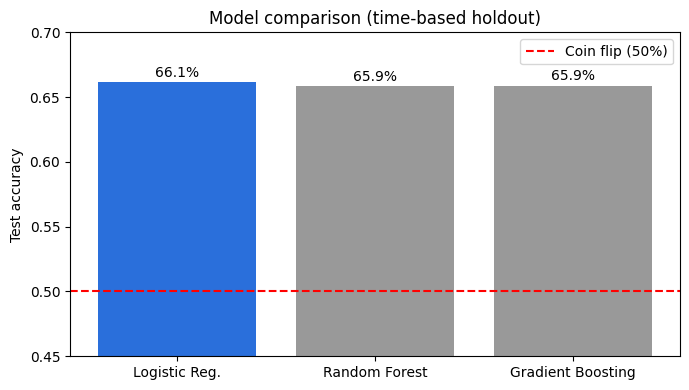

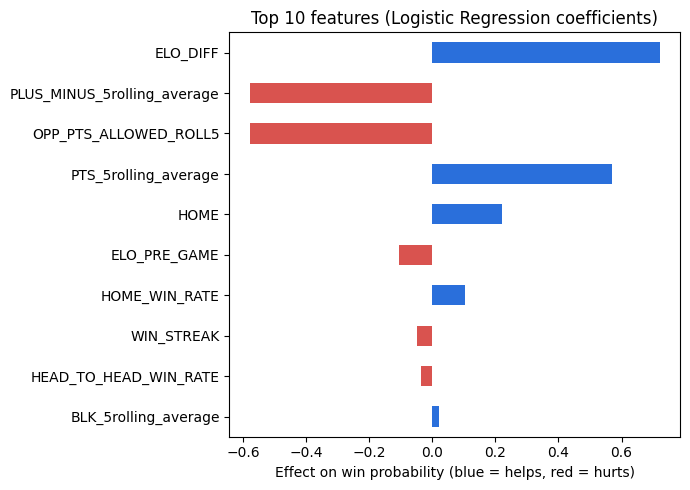

In [132]:
# Now making the README charts

import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

os.makedirs('images', exist_ok=True)

# Chart 1: model comparison
models = ['Logistic\nRegression', 'Random\nForest', 'Gradient\nBoosting']
accs = [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred), accuracy_score(y_test, gb_pred)]
colors = ['#3B6FE0', '#B7C4D9', '#B7C4D9']

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(models, accs, color=colors, width=0.55, edgecolor='white', linewidth=1.5)
ax.axhline(0.5, color='#D9534F', linestyle='--', linewidth=1.2, label='Coin flip (50%)')
ax.set_ylim(0.40, 0.72)
ax.set_ylabel('Accuracy on held-out games', fontsize=11)
ax.set_title('Final model beats the alternatives\non unseen games', fontsize=13, fontweight='bold', pad=14)
ax.yaxis.grid(True, linestyle=':', alpha=0.4)
ax.set_axisbelow(True)
for b, a in zip(bars, accs):
    ax.text(b.get_x() + b.get_width()/2, a + 0.012, f'{a:.1%}', ha='center', fontsize=12, fontweight='bold')
ax.legend(frameon=False, loc='upper right')
plt.tight_layout()
plt.savefig('images/model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

# Chart 2: feature effects
coefs = pd.Series(lr.named_steps['logisticregression'].coef_[0], index=feature_cols)
top = coefs.reindex(coefs.abs().sort_values().tail(10).index)
colors2 = ['#D9534F' if c < 0 else '#3B6FE0' for c in top]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top.values, color=colors2, edgecolor='white', linewidth=1)
ax.axvline(0, color='#333333', linewidth=0.8)
ax.set_title('What drives the prediction\n(logistic regression coefficients, scaled features)', fontsize=13, fontweight='bold', pad=14)
ax.set_xlabel('← lowers win probability      raises win probability →', fontsize=10)
ax.xaxis.grid(True, linestyle=':', alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('images/feature_importance.png', dpi=180, bbox_inches='tight')
plt.show()